In [40]:
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold
import numpy as np
import pandas as pd
import lightgbm as lgb
import time
from itertools import product
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, median_absolute_error, mean_squared_error, r2_score

In [41]:
df = pd.read_csv("cleaned_hospital_data.csv")

In [42]:
df.isna().sum().sum()

0

In [43]:
df.duplicated().sum()

0

In [44]:
df

,Hospital Service Area,Hospital County,Operating Certificate Number,Permanent Facility Id,Facility Name,Age Group,Zip Code - 3 digits,Gender,Race,Ethnicity,...,Emergency Department Indicator,Total Charges,Total Costs,Is_Neonate,Has_Secondary_Insurance,Cost to Charge Ratio,Cost Charge Difference,Has_Procedure,Procedure Prefix,Procedure Code Grouped
0,New York City,Manhattan,7002021,1454,Metropolitan Hospital Center,18 to 29,100,M,Other Race,Spanish/Hispanic,...,Y,21943.33,19793.21,0,0,0.902015,-2150.12,1,OTR,OTR004
1,New York City,Queens,7003000,1626,Elmhurst Hospital Center,50 to 69,113,M,White,Unknown,...,Y,39527.97,18372.44,0,0,0.464796,-21155.53,0,No Procedure,No Code
2,Hudson Valley,Rockland,4324000,776,Montefiore Nyack,70 or Older,109,M,Other Race,Unknown,...,Y,102926.99,25977.53,0,1,0.252388,-76949.46,0,No Procedure,No Code
3,Hudson Valley,Rockland,4324000,776,Montefiore Nyack,50 to 69,109,M,White,Not Span/Hispanic,...,Y,85344.09,18830.76,0,0,0.220645,-66513.33,0,No Procedure,No Code
4,Hudson Valley,Rockland,4324000,776,Montefiore Nyack,70 or Older,109,F,White,Not Span/Hispanic,...,Y,218623.85,42449.25,0,1,0.194166,-176174.60,1,ESA,ESA003
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4208693,New York City,Queens,7003004,3376,Cohen Children's Medical Center,0 to 17,115,M,Other Race,Not Span/Hispanic,...,Y,27074.71,4718.63,0,1,0.174282,-22356.08,0,No Procedure,No Code
4208694,New York City,Queens,7003004,3376,Cohen Children's Medical Center,0 to 17,114,F,Other Race,Not Span/Hispanic,...,N,216053.15,27000.66,1,1,0.124972,-189052.49,0,No Procedure,No Code
4208695,New York City,Queens,7003004,3376,Cohen Children's Medical Center,0 to 17,109,F,White,Not Span/Hispanic,...,Y,24867.76,4291.06,0,1,0.172555,-20576.70,0,No Procedure,No Code
4208696,New York City,Queens,7003004,3376,Cohen Children's Medical Center,0 to 17,117,M,White,Spanish/Hispanic,...,N,46873.00,6210.75,0,1,0.132502,-40662.25,0,No Procedure,No Code


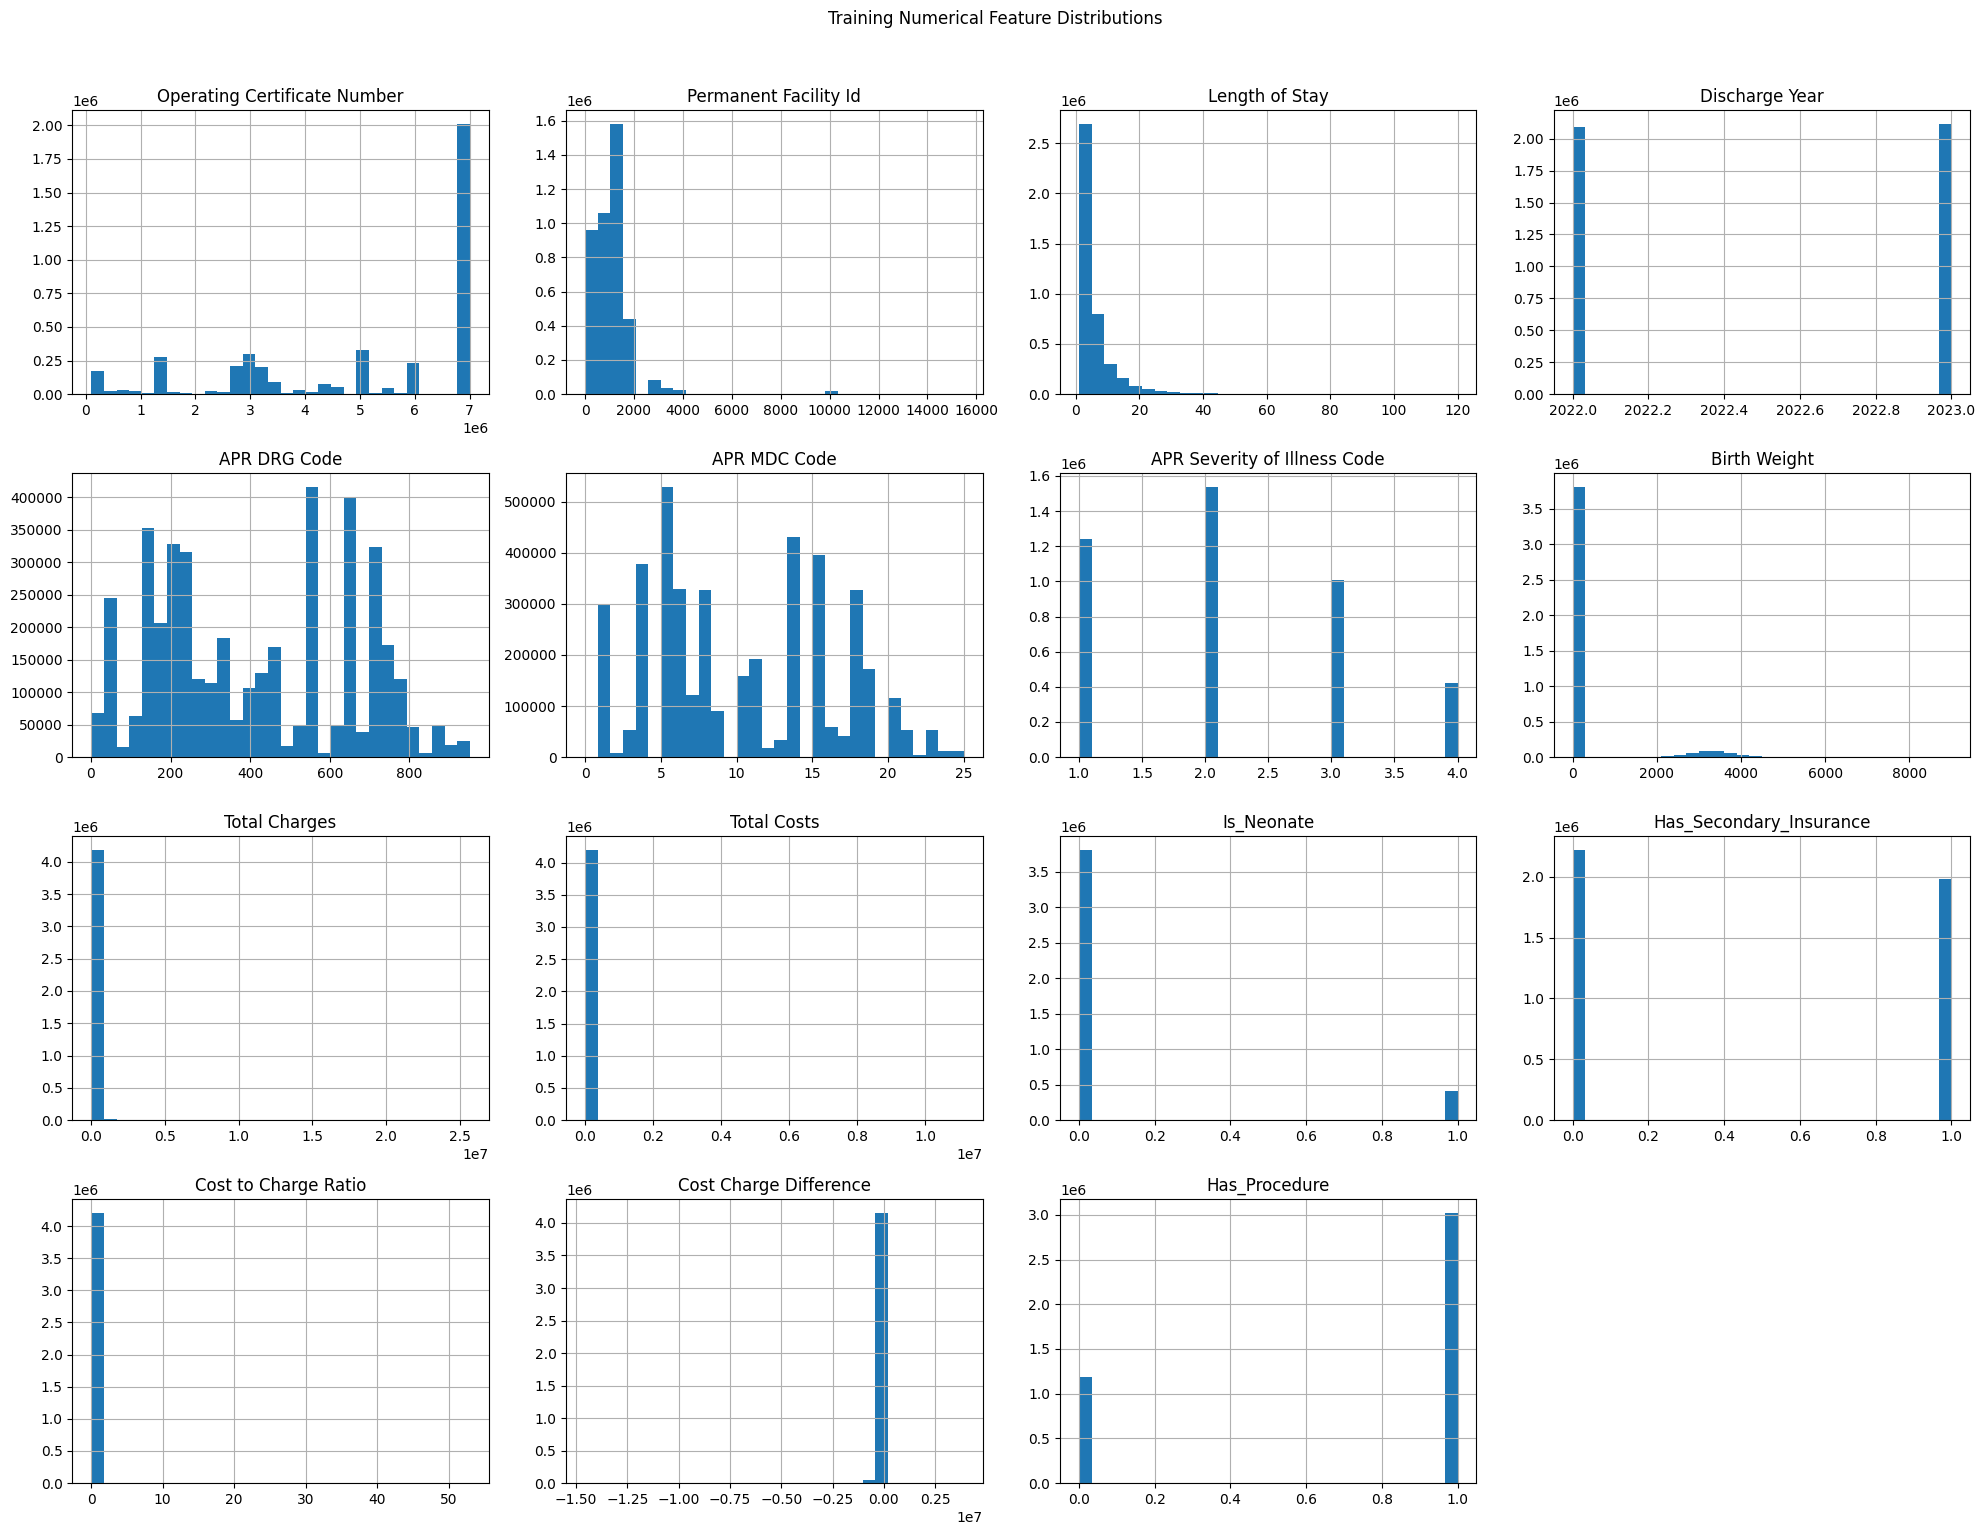

In [45]:
num_cols = df.select_dtypes(include=['int8', 'int16', 'int32', 'int64', 'float64']).columns
df[num_cols].hist(figsize=(20, 15), bins=30)
plt.suptitle('Training Numerical Feature Distributions', y=1.02)
plt.tight_layout()
plt.show()

In [46]:
features_los = [
    # Demographics
    'Age Group', 'Gender', 'Race', 'Ethnicity',
    'Birth Weight',

    # Hospital
    'Hospital County', 'Hospital Service Area',

    # Admission & Insurance
    'Type of Admission', 'Emergency Department Indicator',
    'Payment Typology 1', 'Has_Secondary_Insurance', 'Is_Neonate','Type of Admission','APR DRG Code','Procedure Code Grouped','APR Severity of Illness Code'
    ,'APR Risk of Mortality','Emergency Department Indicator'
]

In [47]:
features_los = list(dict.fromkeys(features_los))
X = df[features_los].copy()

dups = X.columns[X.columns.duplicated()].tolist()
assert not dups, f"Duplicated columns in X: {dups}"
print(type(X['Emergency Department Indicator']))

<class 'pandas.core.series.Series'>


In [48]:
y = df['Length of Stay'].copy()
X = df[features_los].copy()

# ---------- Mappings ----------
age_map = {'0 to 17': 0, '18 to 29': 1, '30 to 49': 2,
           '50 to 69': 3, '70 or Older': 4}
risk_map = {'Undetermined': 0, 'Minor': 1, 'Moderate': 2,
            'Major': 3, 'Extreme': 4}
emergency_map = {'Y': 1, 'N': 0}

X['Age Group'] = X['Age Group'].astype(str).map(age_map)
X['APR Risk of Mortality'] = X['APR Risk of Mortality'].astype(str).map(risk_map)
X['Emergency Department Indicator'] = (
    X['Emergency Department Indicator'].astype(str).map(emergency_map)
)

In [49]:
for c in ['Age Group', 'APR Risk of Mortality', 'Emergency Department Indicator']:
    print(f"{c}: {X[c].isna().sum()} unmapped")

Age Group: 0 unmapped
APR Risk of Mortality: 0 unmapped
Emergency Department Indicator: 0 unmapped


In [50]:
X['Age Group'] = X['Age Group'].astype('float32')
X['APR Risk of Mortality'] = X['APR Risk of Mortality'].astype('float32')
X['Emergency Department Indicator'] = X['Emergency Department Indicator'].astype('float32')
X['Birth Weight'] = X['Birth Weight'].to_numpy(dtype='float32', na_value=np.nan)

In [51]:
nominal_cols = [
    'Gender', 'Race', 'Ethnicity',
    'Hospital Service Area', 'Hospital County',
    'Type of Admission', 'Payment Typology 1',
    'APR DRG Code', 'Procedure Code Grouped',
]
for col in nominal_cols:
    s = X[col].astype('category')
    s = s.cat.rename_categories(lambda c: str(c))
    if s.isna().any():
        s = s.cat.add_categories('Missing').fillna('Missing')
    X[col] = s

In [52]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.01, random_state=42
)
print("Data split and categorical features prepared.")
print(f"X_train rows: {X_train.shape[0]:,} | X_test rows: {X_test.shape[0]:,}")
print(X_train.dtypes)

Data split and categorical features prepared.
X_train rows: 4,166,611 | X_test rows: 42,087
Age Group                          float32
Gender                            category
Race                              category
Ethnicity                         category
Birth Weight                       float32
Hospital County                   category
Hospital Service Area             category
Type of Admission                 category
Emergency Department Indicator     float32
Payment Typology 1                category
Has_Secondary_Insurance              int64
Is_Neonate                           int64
APR DRG Code                      category
Procedure Code Grouped            category
APR Severity of Illness Code         int64
APR Risk of Mortality              float32
dtype: object


In [53]:
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.10, random_state=42
)

In [54]:
t0 = time.time()
m_lgb = lgb.LGBMRegressor(
    objective='regression_l1', n_estimators=1500, learning_rate=0.1,
    num_leaves=127, min_child_samples=50,
    subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
    reg_lambda=1.0, min_data_per_group=100, cat_smooth=20,
    n_jobs=-1, verbosity=-1, random_state=42
)
m_lgb.fit(X_tr, y_tr, eval_set=[(X_val, y_val)], eval_metric='l1',
          callbacks=[lgb.early_stopping(200), lgb.log_evaluation(200)])

c:\Users\Hamza\AppData\Local\Programs\Python\Python312\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 200 rounds
[200]	valid_0's l1: 2.87314
[400]	valid_0's l1: 2.85709
[600]	valid_0's l1: 2.84942
[800]	valid_0's l1: 2.8448
[1000]	valid_0's l1: 2.84172
[1200]	valid_0's l1: 2.83981
[1400]	valid_0's l1: 2.83815
Did not meet early stopping. Best iteration is:
[1500]	valid_0's l1: 2.83723


,boosting_type,'gbdt'
,num_leaves,127
,max_depth,-1
,learning_rate,0.1
,n_estimators,1500
,subsample_for_bin,200000
,objective,'regression_l1'
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,50


In [55]:
y_lo, y_hi = y_train.min(), y_train.max()
test_pred = np.clip(m_lgb.predict(X_test), y_lo, y_hi)
print(f"LightGBM done in {time.time()-t0:.0f}s | best_iter: {m_lgb.best_iteration_}")

LightGBM done in 363s | best_iter: 1500


In [56]:
# ---------- Baseline: median حسب Age Group ----------
base = y_train.groupby(X_train['Age Group'], observed=True).median()
base_pred = (X_test['Age Group'].astype(object).map(base)
             .fillna(y_train.median()).astype(float))
base_pred = np.clip(base_pred, y_lo, y_hi)

In [57]:
summary = pd.DataFrame([
    {'Model': 'LightGBM',
     'MAE': round(mean_absolute_error(y_test, test_pred), 3),
     'MedAE': round(median_absolute_error(y_test, test_pred), 3),
     'RMSE': round(np.sqrt(mean_squared_error(y_test, test_pred)), 3),
     'R2': round(r2_score(y_test, test_pred), 3)},
    {'Model': 'Baseline (median by Age)',
     'MAE': round(mean_absolute_error(y_test, base_pred), 3),
     'MedAE': round(median_absolute_error(y_test, base_pred), 3),
     'RMSE': round(np.sqrt(mean_squared_error(y_test, base_pred)), 3),
     'R2': round(r2_score(y_test, base_pred), 3)},
]).sort_values('MAE').reset_index(drop=True)

print(summary)

                      Model    MAE  MedAE   RMSE     R2
0                  LightGBM  2.834  1.115  6.869  0.398
1  Baseline (median by Age)  3.842  2.000  9.115 -0.060
